# Gridworld policy evaluation

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/reinforcement-learning/02-gridworld-policy-evaluation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

This notebook evaluates a **fixed policy** in a small Gridworld. Fixing the policy turns the Markov decision process (MDP) into a Markov reward process (MRP): at each state, the policy already specifies which action to take or with what probabilities to choose among the actions. The agent follows that rule; there is no policy to choose or learn. Our task is to compute the expected discounted return from each state.

## What we will do

1. Define the same $5 \times 5$ Gridworld used in the course explorers. We use zero-indexed coordinates: the upper-left state is $(0, 0)$ and the lower-right state is $(4, 4)$.
2. Fix a uniform random policy, which selects each of the four actions with probability $1/4$.
3. Build the policy-specific transition matrix $P_\pi$ and expected immediate-reward vector $r_\pi$.
4. Compute $v_\pi$ once by solving a linear system and again through synchronous Bellman expectation updates.

The two methods should agree. The iterative method is the one to keep in mind for later reinforcement-learning algorithms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.image import AxesImage
from numpy.typing import NDArray

# Use the same plotting style as the other course notebooks.
sns.set_theme(style="whitegrid", context="notebook")

## 1. Define the Gridworld environment

The agent can choose up, right, down, or left at every state. Ordinary in-grid moves have reward $0$. An attempted move through the boundary leaves the agent in the same state and gives reward $-1$.

Two source states override the selected direction:

- $A=(0,1)$ sends the agent to $A'=(4,1)$ with reward $+10$.
- $B=(0,3)$ sends the agent to $B'=(2,3)$ with reward $+5$.

The environment is deterministic: once we know a state and an action, the next state and reward are fixed.

In [2]:
GRID_SIZE = 5
GAMMA = 0.9
State = tuple[int, int]  # (row, column)

# The action order matches the course exploration pages.
ACTIONS = [
    ("up", -1, 0, "↑"),
    ("right", 0, 1, "→"),
    ("down", 1, 0, "↓"),
    ("left", 0, -1, "←"),
]

A = (0, 1)
A_PRIME = (4, 1)
B = (0, 3)
B_PRIME = (2, 3)

TELEPORTS = {
    A: (A_PRIME, 10.0),
    B: (B_PRIME, 5.0),
}


def in_grid(state: State) -> bool:
    """Return True when a zero-indexed state lies inside the 5-by-5 grid."""
    row, column = state
    return 0 <= row < GRID_SIZE and 0 <= column < GRID_SIZE


def transition(state: State, action_index: int) -> tuple[State, float]:
    """Return (next_state, reward) after taking one action from one state."""
    # A and B are special source states: every action has the same outcome.
    if state in TELEPORTS:
        return TELEPORTS[state]

    _, row_change, column_change, _ = ACTIONS[action_index]
    row, column = state
    candidate = (row + row_change, column + column_change)

    # A boundary action is a self-loop with reward -1.
    if not in_grid(candidate):
        return state, -1.0

    # Every ordinary in-grid transition has reward 0.
    return candidate, 0.0


def state_to_index(state: State) -> int:
    """Map (row, column) to one of the 25 entries of a value vector."""
    row, column = state
    return row * GRID_SIZE + column


def index_to_state(index: int) -> State:
    """Inverse of state_to_index."""
    return divmod(index, GRID_SIZE)

A few transitions make the rules concrete. Notice that the action is still listed at $A$ and $B$, even though it does not affect their teleport outcome.

In [3]:
examples = [
    ((0, 0), 0),  # Up from the upper-left corner: boundary self-loop
    ((0, 0), 1),  # Right into A: ordinary move with reward 0
    (A, 2),       # Down from A: forced teleport
    (B, 3),       # Left from B: forced teleport
]

for state, action_index in examples:
    action_name = ACTIONS[action_index][0]
    next_state, reward = transition(state, action_index)
    print(f"{state} + {action_name:>5s}  ->  {next_state}, reward = {reward:+.0f}")

(0, 0) +    up  ->  (0, 0), reward = -1
(0, 0) + right  ->  (0, 1), reward = +0
(0, 1) +  down  ->  (4, 1), reward = +10
(0, 3) +  left  ->  (2, 3), reward = +5


## 2. Fix a uniform random policy

For this notebook, the agent follows the same policy at every state:

$$
\pi_{\mathrm{random}}(a \mid s) = \frac{1}{4},
\qquad
a \in \{\uparrow, \rightarrow, \downarrow, \leftarrow\}.
$$

This makes the Gridworld an MRP. The Bellman expectation equation becomes

$$
v_\pi(s) = \sum_a \pi(a \mid s)
\left[r(s,a,s') + \gamma v_\pi(s')\right],
$$

because this particular environment has a single deterministic outcome $(s',r)$ for each state-action pair.

In [4]:
N_STATES = GRID_SIZE * GRID_SIZE
N_ACTIONS = len(ACTIONS)

# policy[row, column, action] stores pi(action | state).
random_policy = np.full(
    (GRID_SIZE, GRID_SIZE, N_ACTIONS),
    fill_value=1 / N_ACTIONS,
)


def build_policy_model(
    policy: NDArray[np.float64],
) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    """Build P_pi and r_pi for a fixed policy in this deterministic Gridworld."""
    transition_matrix = np.zeros((N_STATES, N_STATES))
    expected_rewards = np.zeros(N_STATES)

    for row in range(GRID_SIZE):
        for column in range(GRID_SIZE):
            state = (row, column)
            state_index = state_to_index(state)

            for action_index in range(N_ACTIONS):
                probability = policy[row, column, action_index]
                next_state, reward = transition(state, action_index)
                next_index = state_to_index(next_state)

                # Average the transition and immediate reward over policy actions.
                transition_matrix[state_index, next_index] += probability
                expected_rewards[state_index] += probability * reward

    return transition_matrix, expected_rewards


P_pi, r_pi = build_policy_model(random_policy)

print("P_pi shape:", P_pi.shape)
print("Every row of P_pi sums to one:", np.allclose(P_pi.sum(axis=1), 1.0))
print(f"Expected immediate reward at (0, 0): {r_pi[state_to_index((0, 0))]:+.2f}")
print(f"Expected immediate reward at A={A}: {r_pi[state_to_index(A)]:+.2f}")

P_pi shape: (25, 25)
Every row of P_pi sums to one: True
Expected immediate reward at (0, 0): -0.50
Expected immediate reward at A=(0, 1): +10.00


The expected reward at $(0,0)$ is $-0.5$: two of the four random actions hit a boundary and receive $-1$. At $A$, every action produces the $+10$ teleport reward.

In vector form, the Bellman expectation equation for this fixed policy is

$$
\mathbf{v}_\pi = \mathbf{r}_\pi + \gamma P_\pi \mathbf{v}_\pi,
$$

or equivalently,

$$
(I - \gamma P_\pi)\mathbf{v}_\pi = \mathbf{r}_\pi.
$$

## 3. Solve the value function directly

This Gridworld has only 25 states, so we can solve the linear system directly. We use <code>np.linalg.solve</code>, which solves the system without explicitly forming a matrix inverse.

In [5]:
identity = np.eye(N_STATES)
v_direct = np.linalg.solve(identity - GAMMA * P_pi, r_pi)
V_direct = v_direct.reshape(GRID_SIZE, GRID_SIZE)

print("Direct-solve value at A:", round(V_direct[A], 3))
print("Direct-solve value at B:", round(V_direct[B], 3))

Direct-solve value at A: 8.789
Direct-solve value at B: 5.322


### Plot the state values

Reshaping the solution into a grid lets us see how expected returns vary by state. Red indicates higher values, white is near zero, and blue indicates lower values.

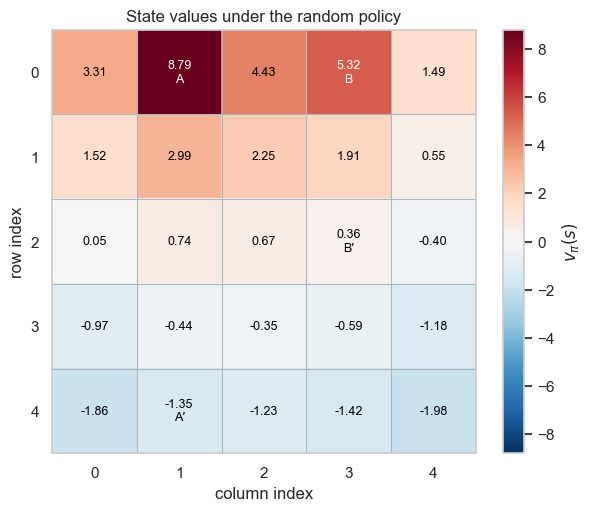

In [6]:
def draw_value_grid(
    values: NDArray[np.float64],
    title: str,
    ax: Axes,
    *,
    value_limit: float | None = None,
) -> AxesImage:
    """Draw a zero-indexed Gridworld value table on one Matplotlib axis."""
    if value_limit is None:
        value_limit = float(np.max(np.abs(values)))
    image = ax.imshow(values, cmap="RdBu_r", vmin=-value_limit, vmax=value_limit)
    ax.set_title(title)
    ax.set_xlabel("column index")
    ax.set_ylabel("row index")
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))

    # Cell centers carry the labels; half-integers are the boundaries.
    boundaries = np.arange(0.5, GRID_SIZE - 1)
    ax.set_xticks(boundaries, minor=True)
    ax.set_yticks(boundaries, minor=True)
    ax.grid(False, which="major")
    ax.grid(True, which="minor", color="#aeb6bf", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    special_labels = {A: "A", A_PRIME: "A′", B: "B", B_PRIME: "B′"}
    for row in range(GRID_SIZE):
        for column in range(GRID_SIZE):
            state = (row, column)
            label = f"{values[row, column]:.2f}"
            if state in special_labels:
                label += f"\n{special_labels[state]}"
            red, green, blue, _ = image.cmap(image.norm(values[state]))
            brightness = 0.2126 * red + 0.7152 * green + 0.0722 * blue
            text_color = "white" if brightness < 0.5 else "black"
            ax.text(column, row, label, ha="center", va="center", fontsize=9, color=text_color)

    return image


fig, ax = plt.subplots(figsize=(7, 5.5))
image = draw_value_grid(V_direct, "State values under the random policy", ax)
fig.colorbar(image, ax=ax, label=r"$v_\pi(s)$")
plt.show()

The direct solve gives the exact state values for this known finite MRP. It is useful as a reference, but it relies on having the complete transition model and becomes impractical for large state spaces.

## 4. Estimate the same value function iteratively

Instead of solving all 25 equations at once, start from $\mathbf{v}_0=0$ and repeatedly apply

$$
\mathbf{v}_{k+1} = \mathbf{r}_\pi + \gamma P_\pi \mathbf{v}_k.
$$

Each update below is **synchronous**: every value in $\mathbf{v}_{k+1}$ uses the complete previous vector $\mathbf{v}_k$. The maximum absolute change tells us when the estimates have stabilized.

In [7]:
def evaluate_policy_synchronously(
    P_pi: NDArray[np.float64],
    r_pi: NDArray[np.float64],
    gamma: float,
    tolerance: float = 1e-4,
    max_sweeps: int = 10_000,
) -> tuple[NDArray[np.float64], list[NDArray[np.float64]], NDArray[np.float64]]:
    """Estimate v_pi with synchronous Bellman expectation backups."""
    values = np.zeros(N_STATES)
    value_history = [values.copy()]
    max_changes = []

    for _ in range(max_sweeps):
        # Matrix multiplication uses only the old value vector on the right.
        updated_values = r_pi + gamma * (P_pi @ values)
        max_change = np.max(np.abs(updated_values - values))

        values = updated_values
        value_history.append(values.copy())
        max_changes.append(max_change)

        if max_change < tolerance:
            break
    else:
        raise RuntimeError("The value estimates did not converge within max_sweeps.")

    return values, value_history, np.asarray(max_changes)


v_iterative, history, max_changes = evaluate_policy_synchronously(
    P_pi,
    r_pi,
    gamma=GAMMA,
)
V_iterative = v_iterative.reshape(GRID_SIZE, GRID_SIZE)

print(f"Converged after {len(max_changes)} synchronous Bellman sweeps.")
print(f"Final maximum change: {max_changes[-1]:.2e}")
print(f"Maximum absolute difference from the direct solution: {np.max(np.abs(V_iterative - V_direct)):.2e}")

Converged after 47 synchronous Bellman sweeps.
Final maximum change: 9.10e-05
Maximum absolute difference from the direct solution: 8.06e-04


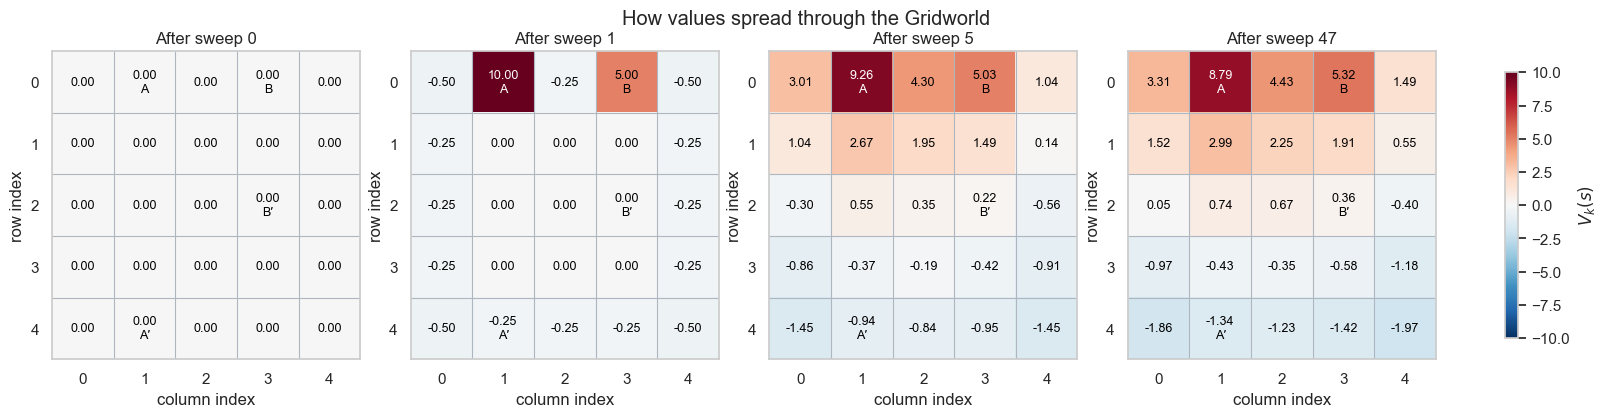

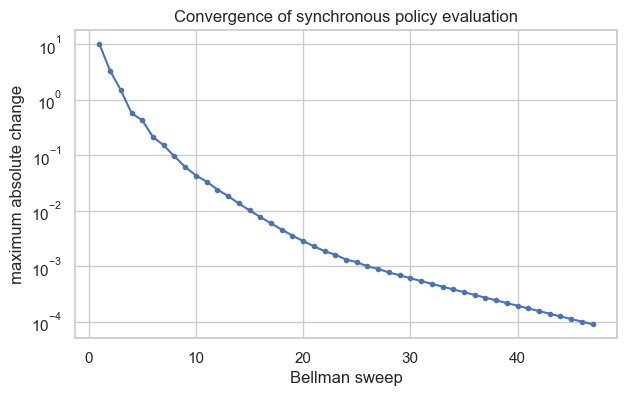

In [8]:
snapshot_indices = [0, 1, 5, len(history) - 1]
value_limit = float(max(np.max(np.abs(snapshot)) for snapshot in history))

fig, axes = plt.subplots(
    1,
    len(snapshot_indices),
    figsize=(16, 4),
    constrained_layout=True,
)
for ax, sweep_index in zip(axes, snapshot_indices):
    snapshot = history[sweep_index].reshape(GRID_SIZE, GRID_SIZE)
    image = draw_value_grid(
        snapshot,
        f"After sweep {sweep_index}",
        ax,
        value_limit=value_limit,
    )

fig.colorbar(image, ax=axes, shrink=0.8, label="$V_k(s)$")
fig.suptitle("How values spread through the Gridworld")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(1, len(max_changes) + 1), max_changes, marker="o", markersize=3)
ax.set_xlabel("Bellman sweep")
ax.set_ylabel("maximum absolute change")
ax.set_title("Convergence of synchronous policy evaluation")
plt.show()

### Optional: What if updates were asynchronous?

In a **synchronous** sweep, every state reads from the same previous value grid. In an **asynchronous** update, we can update one state at a time in place, using the latest available values. For example, if we update $(0,0)$ first, the backup at $(1,0)$ can immediately use its new value for the action that moves up.

The Bellman equation and the fixed policy stay the same. Here, with $\gamma < 1$, both approaches converge to the same state values if every state keeps getting updated. The intermediate estimates can differ depending on the update order.

## Takeaways

- A fixed policy turns this MDP into an MRP with one value $v_\pi(s)$ for every state.
- For a small known MRP, a linear-system solve and iterative Bellman expectation updates produce the same values.
- The iterative method repeatedly propagates immediate rewards and discounted future values through the state space.
- In the next notebook, the agent will improve the policy rather than merely evaluate a fixed one.

[← Return to Reinforcement learning](index.qmd)